In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(r"C:\Users\jcami\OneDrive\Escritorio\fisher-rao-graph-clustering\results_quick")

In [29]:
import numpy as np
import matplotlib.pyplot as plt


METHOD_STYLES = {
    "hellinger": {
        "label": "A (Hellinger)",
        "marker": "o", "linestyle": "-",
        "color": "black",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
    },
    "tangent": {
        "label": "B (Tangent)",
        "marker": "s", "linestyle": "--",
        "color": "dimgray",
        "markerfacecolor": "white",
        "markeredgecolor": "dimgray",
    },
    "segment": {
        "label": "C (Segment)",
        "marker": "^", "linestyle": ":",
        "color": "firebrick",
        "markerfacecolor": "white",
        "markeredgecolor": "firebrick",
    },
    "euclidean": {
        "label": "D (Euclidean)",
        "marker": "D", "linestyle": "-.",
        "color": "darkgreen",
        "markerfacecolor": "white",
        "markeredgecolor": "darkgreen",
    },
}

DEFAULT_METHOD_ORDER = ["hellinger", "tangent", "segment", "euclidean"]

DEFAULT_TITLES = {
    "U":  "Uniform",
    "M2": "Moderate (2 clusters)",
    "M3": "Moderate (3 clusters)",
    "L2": "Large (2 clusters)",
    "L3": "Large (3 clusters)",
}


def plot_grid_by_method(summary,
                        regimes=("U", "M2", "M3", "L3"),
                        methods=DEFAULT_METHOD_ORDER,
                        show_ci=True,
                        ci_columns=("LB", "UB"),
                        ylim=(0.85, 1.005),
                        figsize=(6, 5),
                        xlabel="Sample size (n)",
                        ylabel=r"Expected $\rho$",
                        xlabel_pad=6.0, ylabel_pad=4.0,
                        titles=None,
                        suptitle=None,
                        suptitle_fontsize=9,
                        wspace=0.1, hspace=0.3,
                        title_fontsize=7,
                        legend_kwargs=None,
                        legend_panel=1):
    """
    Grafica mean ± IC para cada régimen. Grid 2x2.
    Los regímenes se pasan en `regimes` (debe ser una tupla de a lo más 4).

    Parámetros
    ----------
    suptitle : str o None
        Título general de la figura. Si es None, no se dibuja.
    suptitle_fontsize : float
        Tamaño de la fuente del suptitle.
    """
    if titles is None:
        titles = DEFAULT_TITLES
    if legend_kwargs is None:
        legend_kwargs = {"frameon": False, "loc": "lower right",
                         "fontsize": 6}

    fig, axs = plt.subplots(2, 2, figsize=figsize)
    axs_flat = axs.flatten()

    for idx, ax in enumerate(axs_flat):
        if idx >= len(regimes):
            ax.set_visible(False)
            continue

        regime = regimes[idx]
        row, col = idx // 2, idx % 2
        sub_reg = summary[summary["regime"] == regime]

        for method in methods:
            sub = sub_reg[sub_reg["method"] == method].sort_values("n")
            if sub.empty:
                continue

            style = METHOD_STYLES.get(method, {
                "label": method, "marker": "o", "linestyle": "-",
                "color": "black", "markerfacecolor": "black",
                "markeredgecolor": "black",
            })

            ns    = sub["n"].to_numpy(dtype=float)
            means = sub["mean"].to_numpy(dtype=float)

            if show_ci:
                lo = sub[ci_columns[0]].to_numpy(dtype=float)
                hi = sub[ci_columns[1]].to_numpy(dtype=float)
                yerr = np.vstack([means - lo, hi - means])
                ax.errorbar(
                    ns, means, yerr=yerr,
                    marker=style["marker"],
                    linestyle=style["linestyle"],
                    color=style["color"],
                    markerfacecolor=style["markerfacecolor"],
                    markeredgecolor=style["markeredgecolor"],
                    markersize=4, linewidth=1.0,
                    capsize=3, capthick=0.8, elinewidth=0.8,
                    label=style["label"],
                )
            else:
                ax.plot(
                    ns, means,
                    marker=style["marker"],
                    linestyle=style["linestyle"],
                    color=style["color"],
                    markerfacecolor=style["markerfacecolor"],
                    markeredgecolor=style["markeredgecolor"],
                    markersize=4, linewidth=1.0,
                    label=style["label"],
                )

        ax.set_title(titles.get(regime, regime), fontsize=title_fontsize)
        ax.set_ylim(*ylim)
        ax.set_xscale("log")
        ax.grid(False)

        if row == 0:
            ax.set_xlabel('')
            ax.tick_params(axis='x', which='both', labelbottom=False)
        else:
            ax.set_xlabel(xlabel, labelpad=xlabel_pad)

        if col == 0:
            ax.set_ylabel(ylabel, labelpad=ylabel_pad)
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', which='both', labelleft=False)

        if idx == legend_panel:
            ax.legend(**legend_kwargs)

    if suptitle is not None:
        fig.suptitle(suptitle, fontsize=suptitle_fontsize, y=0.98)
        plt.subplots_adjust(wspace=wspace, hspace=hspace, top=0.90)
    else:
        plt.subplots_adjust(wspace=wspace, hspace=hspace)

    plt.show()
    return fig, axs

In [42]:
import numpy as np
import pandas as pd


def build_summary_delta(df, crit_order=None):
    """
    Análogo a build_summary, pero para delta_rel_err.
    Devuelve un DataFrame con régimen, método, N, mean, LB, UB.
    Excluye Euclídea por defecto (no comparable).
    """
    if crit_order is None:
        crit_order = ["hellinger", "tangent", "segment"]

    rows = []
    for reg in sorted(df["regime"].unique()):
        sub = df[df["regime"] == reg]
        for crit in crit_order:
            sub_c = sub[sub["criterion"] == crit]
            for N in sorted(sub_c["N"].unique()):
                sub_n = sub_c[sub_c["N"] == N]

                per_rep = sub_n.groupby("rep")["delta_rel_err"].mean().to_numpy()
                R  = len(per_rep)
                m  = per_rep.mean()
                se = per_rep.std(ddof=1) / np.sqrt(R) if R > 1 else 0.0

                rows.append({
                    "regime": reg, "method": crit, "n": N,
                    "mean": m, "LB": m - se, "UB": m + se, "se": se,
                })
    return pd.DataFrame(rows)


summaries_delta = {
    "Gaussian": build_summary_delta(g_gaussian),
    "Gamma":    build_summary_delta(g_gamma),
    "Beta":     build_summary_delta(g_beta),
}

print(summaries_delta["Gamma"].head())

  regime     method    n      mean        LB        UB        se
0     L3  hellinger   10  0.001489  0.001312  0.001666  0.000177
1     L3  hellinger   30  0.000601  0.000462  0.000740  0.000139
2     L3  hellinger   50  0.000430  0.000362  0.000499  0.000068
3     L3  hellinger   80  0.000452  0.000347  0.000557  0.000105
4     L3  hellinger  100  0.000345  0.000285  0.000405  0.000060


In [4]:
dfs = []
for csv in sorted(ROOT.glob("Gaussian_*.csv")):
    if ".timing." in csv.name:
        continue
    family, regime, rep = csv.stem.split("_")  # Gaussian_M2_0
    df = pd.read_csv(csv)
    df["family"] = family
    df["regime"] = regime
    df["rep"]    = int(rep)
    dfs.append(df)

pts = pd.concat(dfs, ignore_index=True)

# Excluir el bloque de auto-referencia (rho=1, mismo delta en h y f)
work = pts[pts["criterion"] != "fr"].copy()

# Errores relativos por punto
work["delta_rel_err"] = (work["delta_h"] - work["delta_f"]).abs() / work["delta_f"]
for k in range(1, 10):
    work[f"rk{k}_rel_err"] = (
        (work[f"r_h_{k}"] - work[f"r_f_{k}"]).abs() / work[f"r_f_{k}"]
    )

print(f"puntos totales: {len(work):,}")
print(f"combinaciones: {work.groupby(['regime','N','criterion']).ngroups}")
work.head(3)

puntos totales: 16,200
combinaciones: 60


,N,criterion,i,rho,delta_h,delta_f,r_h_1,r_f_1,r_h_2,r_f_2,...,delta_rel_err,rk1_rel_err,rk2_rel_err,rk3_rel_err,rk4_rel_err,rk5_rel_err,rk6_rel_err,rk7_rel_err,rk8_rel_err,rk9_rel_err
10,10,hellinger,0,0.950000,0.259929,0.258598,0.259929,0.258598,3.611168,3.005968,...,0.005147,0.005147,0.201333,0.243068,0.318011,0.291377,0.679994,0.671440,0.638607,0.658241
11,10,hellinger,1,0.950000,0.259929,0.258598,0.259929,0.258598,3.810111,3.099568,...,0.005147,0.005147,0.229239,0.242937,0.298592,0.318396,0.818455,0.786260,0.774593,0.788159
12,10,hellinger,2,0.916667,0.303820,0.301537,0.303820,0.301537,0.802420,0.765196,...,0.007572,0.007572,0.048646,0.083940,0.318011,0.298592,0.711429,0.746819,0.779581,0.752795


In [5]:
# Celda 1: promedio por réplica, luego media y SE entre réplicas
# ────────────────────────────────────────────────────────────────
crit_order = ["hellinger", "tangent", "segment", "euclidean"]
labels     = ["A (Hellinger)", "B (Tangent)", "C (Segment)", "D (Euclidean)"]

# 1. Media por (regime, N, criterion, rep) sobre los puntos
per_rep = (work
    .groupby(["regime", "N", "criterion", "rep"])["rho"]
    .mean()
    .reset_index()
)

# 2. Media y SE entre réplicas
agg = (per_rep
    .groupby(["regime", "N", "criterion"])["rho"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)
agg["se"] = agg["std"] / np.sqrt(agg["n"])

# 3. Formatear cada celda como "mean ± se"
agg["cell"] = agg.apply(
    lambda r: f"{r['mean']:.3f} ± {r['se']:.3f}", axis=1
)

# 4. Función de tabla por régimen
def table_for_regime(regime):
    sub = agg[agg["regime"] == regime]
    tbl = sub.pivot_table(index="N", columns="criterion", values="cell", aggfunc="first")
    return tbl.reindex(columns=crit_order).rename(columns=dict(zip(crit_order, labels)))

for reg in sorted(work["regime"].unique()):
    print(f"=== Gaussian · régimen {reg} ===")
    print(table_for_regime(reg))
    print()

=== Gaussian · régimen L3 ===
criterion  A (Hellinger)    B (Tangent)    C (Segment)  D (Euclidean)
N                                                                    
10         0.945 ± 0.019  0.968 ± 0.012  0.992 ± 0.006  0.898 ± 0.015
30         0.974 ± 0.008  0.987 ± 0.004  0.997 ± 0.001  0.925 ± 0.006
50         0.980 ± 0.006  0.991 ± 0.002  0.999 ± 0.000  0.929 ± 0.007
80         0.980 ± 0.005  0.991 ± 0.002  0.999 ± 0.000  0.928 ± 0.007
100        0.981 ± 0.004  0.992 ± 0.002  0.999 ± 0.000  0.930 ± 0.006

=== Gaussian · régimen M2 ===
criterion  A (Hellinger)    B (Tangent)    C (Segment)  D (Euclidean)
N                                                                    
10         0.993 ± 0.005  0.995 ± 0.003  1.000 ± 0.000  0.846 ± 0.024
30         0.997 ± 0.001  0.999 ± 0.000  1.000 ± 0.000  0.900 ± 0.024
50         0.997 ± 0.001  0.999 ± 0.001  1.000 ± 0.000  0.900 ± 0.025
80         0.998 ± 0.001  0.999 ± 0.000  1.000 ± 0.000  0.907 ± 0.024
100        0.997 ± 0.001  0.9

In [7]:
# Media sobre los tres regímenes para cada (N, criterion)
per_cell = (work
    .groupby(["N", "criterion", "regime", "rep"])["rho"]
    .mean()
    .reset_index()
)

agg_all = (per_cell
    .groupby(["N", "criterion"])["rho"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)
agg_all["se"] = agg_all["std"] / np.sqrt(agg_all["n"])
agg_all["cell"] = agg_all.apply(
    lambda r: f"{r['mean']:.3f} ± {r['se']:.3f}", axis=1
)

crit_order = ["hellinger", "tangent", "segment", "euclidean"]
labels     = ["A (Hellinger)", "B (Tangent)", "C (Segment)", "D (Euclidean)"]

tbl = (agg_all
    .pivot_table(index="N", columns="criterion", values="cell", aggfunc="first")
    .reindex(columns=crit_order)
    .rename(columns=dict(zip(crit_order, labels)))
)

print(tbl)

criterion  A (Hellinger)    B (Tangent)    C (Segment)  D (Euclidean)
N                                                                    
10         0.967 ± 0.009  0.979 ± 0.006  0.996 ± 0.002  0.870 ± 0.015
30         0.986 ± 0.004  0.993 ± 0.002  0.998 ± 0.000  0.913 ± 0.008
50         0.989 ± 0.003  0.995 ± 0.001  0.999 ± 0.000  0.917 ± 0.009
80         0.989 ± 0.003  0.995 ± 0.001  0.999 ± 0.000  0.918 ± 0.008
100        0.990 ± 0.002  0.995 ± 0.001  0.999 ± 0.000  0.917 ± 0.009


In [18]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(r"C:\Users\jcami\OneDrive\Escritorio\fisher-rao-graph-clustering\results_quick")

# Cargar solo los CSV de puntos de Gamma
dfs = []
for csv in sorted(ROOT.glob("Gamma_*.csv")):
    if ".timing." in csv.name:
        continue
    parts = csv.stem.split("_")   # "Gamma_M2_0"
    family, regime, rep = parts[0], parts[1], int(parts[2])
    df = pd.read_csv(csv)
    df["family"] = family
    df["regime"] = regime
    df["rep"]    = rep
    dfs.append(df)

g_gamma = pd.concat(dfs, ignore_index=True)
print(f"puntos Gamma: {len(g_gamma):,}")
print(g_gamma["regime"].value_counts())
print(g_gamma["N"].value_counts().sort_index())

# Excluir el bloque auto-referencia (criterion == "fr")
g_gamma = g_gamma[g_gamma["criterion"] != "fr"].copy()

# Error relativo del radio δ
g_gamma["delta_rel_err"] = (
    (g_gamma["delta_h"] - g_gamma["delta_f"]).abs() / g_gamma["delta_f"]
)
for k in range(1, 10):
    g_gamma[f"rk{k}_rel_err"] = (
        (g_gamma[f"r_h_{k}"] - g_gamma[f"r_f_{k}"]).abs() / g_gamma[f"r_f_{k}"]
    )

g_gamma.head(3)

puntos Gamma: 20,250
regime
L3    6750
M2    6750
U     6750
Name: count, dtype: int64
N
10      750
30     2250
50     3750
80     6000
100    7500
Name: count, dtype: int64


,N,criterion,i,rho,delta_h,delta_f,r_h_1,r_f_1,r_h_2,r_f_2,...,delta_rel_err,rk1_rel_err,rk2_rel_err,rk3_rel_err,rk4_rel_err,rk5_rel_err,rk6_rel_err,rk7_rel_err,rk8_rel_err,rk9_rel_err
10,10,hellinger,0,1.0,0.036910,0.036907,0.036910,0.036907,0.219266,0.218545,...,0.000086,0.000086,0.003300,0.003025,0.044805,0.055149,0.055705,0.057290,0.040962,0.027423
11,10,hellinger,1,1.0,0.036910,0.036907,0.036910,0.036907,0.184301,0.183889,...,0.000086,0.000086,0.002238,0.003218,0.048189,0.050412,0.050925,0.052438,0.044065,0.028232
12,10,hellinger,2,1.0,0.015558,0.015558,0.015558,0.015558,0.118687,0.118605,...,0.000022,0.000022,0.000695,0.033443,0.053235,0.052438,0.057290,0.122613,0.157443,0.163461


In [20]:
crit_order = ["hellinger", "tangent", "segment", "euclidean"]
labels     = ["A (Hellinger)", "B (Tangent)", "C (Segment)", "D (Euclidean)"]

# Promedio por (régimen, N, criterio, réplica) sobre los puntos
per_cell = (g_gamma
    .groupby(["regime", "N", "criterion", "rep"])["rho"]
    .mean()
    .reset_index()
)

# Media y SE entre réplicas, agregando sobre los regímenes
agg_all = (per_cell
    .groupby(["N", "criterion"])["rho"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)
agg_all["se"]  = agg_all["std"] / np.sqrt(agg_all["n"])
agg_all["cell"] = agg_all.apply(
    lambda r: f"{r['mean']:.3f} ± {r['se']:.3f}", axis=1
)

tbl = (agg_all
    .pivot_table(index="N", columns="criterion", values="cell", aggfunc="first")
    .reindex(columns=crit_order)
    .rename(columns=dict(zip(crit_order, labels)))
)

print("=== Gamma · media sobre regímenes ===")
print(tbl)

=== Gamma · media sobre regímenes ===
criterion  A (Hellinger)    B (Tangent)    C (Segment)  D (Euclidean)
N                                                                    
10         0.993 ± 0.002  0.972 ± 0.006  0.982 ± 0.005  0.892 ± 0.020
30         0.995 ± 0.001  0.984 ± 0.003  0.994 ± 0.001  0.910 ± 0.013
50         0.996 ± 0.001  0.987 ± 0.002  0.995 ± 0.001  0.917 ± 0.012
80         0.997 ± 0.001  0.988 ± 0.002  0.996 ± 0.001  0.917 ± 0.011
100        0.997 ± 0.001  0.989 ± 0.002  0.996 ± 0.001  0.918 ± 0.010


In [21]:
# Media del error relativo de r_k por (N, criterion, k), agregado sobre regímenes y réplicas.
# Para cada punto i y cada k, el error relativo es |r_h_k − r_f_k| / r_f_k.

crit_order = ["hellinger", "tangent", "segment", "euclidean"]
labels     = ["A (Hellinger)", "B (Tangent)", "C (Segment)", "D (Euclidean)"]

rows = []
for k in range(1, 10):
    col = f"rk{k}_rel_err"
    sub = (g_gamma
        .groupby(["N", "criterion", "regime", "rep"])[col]
        .mean()
        .reset_index()
        .groupby(["N", "criterion"])[col]
        .agg(mean="mean", std="std", n="count")
        .reset_index()
    )
    sub["se"]   = sub["std"] / np.sqrt(sub["n"])
    sub["k"]    = k
    sub["cell"] = sub.apply(lambda r: f"{r['mean']:.4f} ± {r['se']:.4f}", axis=1)
    rows.append(sub)

rk = pd.concat(rows, ignore_index=True)

# Tabla 1: para N=100, cómo varía el error con k, por criterio
print("=== Gamma · error relativo de r_k, N=100 ===")
tbl_k = (rk[rk["N"] == 100]
    .pivot_table(index="k", columns="criterion", values="cell", aggfunc="first")
    .reindex(columns=crit_order)
    .rename(columns=dict(zip(crit_order, labels)))
)
print(tbl_k)
print()

# Tabla 2: para k=1 y k=9, cómo varía el error con N, por criterio
for kk in [1, 9]:
    print(f"=== Gamma · error relativo de r_{kk}, por N ===")
    tbl_N = (rk[rk["k"] == kk]
        .pivot_table(index="N", columns="criterion", values="cell", aggfunc="first")
        .reindex(columns=crit_order)
        .rename(columns=dict(zip(crit_order, labels)))
    )
    print(tbl_N)
    print()

=== Gamma · error relativo de r_k, N=100 ===
criterion    A (Hellinger)      B (Tangent)      C (Segment)    D (Euclidean)
k                                                                            
1          0.0006 ± 0.0001  0.0019 ± 0.0003  0.0003 ± 0.0000  1.5183 ± 0.0543
2          0.0011 ± 0.0002  0.0036 ± 0.0007  0.0006 ± 0.0001  1.5123 ± 0.0516
3          0.0015 ± 0.0003  0.0049 ± 0.0010  0.0007 ± 0.0001  1.5088 ± 0.0634
4          0.0021 ± 0.0005  0.0070 ± 0.0016  0.0011 ± 0.0002  1.4718 ± 0.0620
5          0.0026 ± 0.0006  0.0084 ± 0.0020  0.0014 ± 0.0004  1.4426 ± 0.0642
6          0.0031 ± 0.0008  0.0101 ± 0.0024  0.0016 ± 0.0004  1.4193 ± 0.0642
7          0.0036 ± 0.0009  0.0116 ± 0.0029  0.0018 ± 0.0005  1.4073 ± 0.0615
8          0.0038 ± 0.0010  0.0127 ± 0.0032  0.0019 ± 0.0005  1.3946 ± 0.0629
9          0.0045 ± 0.0012  0.0147 ± 0.0038  0.0024 ± 0.0006  1.3862 ± 0.0646

=== Gamma · error relativo de r_1, por N ===
criterion    A (Hellinger)      B (Tangent)      C 

In [25]:
dfs = []
for csv in sorted(ROOT.glob("*_*.csv")):
    if ".timing." in csv.name:
        continue
    parts = csv.stem.split("_")
    if len(parts) != 3:
        continue
    family, regime, rep = parts[0], parts[1], int(parts[2])
    df = pd.read_csv(csv)
    df["family"] = family
    df["regime"] = regime
    df["rep"]    = rep
    dfs.append(df)

all_pts = pd.concat(dfs, ignore_index=True)
all_pts = all_pts[all_pts["criterion"] != "fr"].copy()
all_pts["delta_rel_err"] = (
    (all_pts["delta_h"] - all_pts["delta_f"]).abs()
    / all_pts["delta_f"]
)

# Tres DataFrames por familia, listos para el plot
g_gaussian = all_pts[all_pts["family"] == "Gaussian"].copy()
g_gamma    = all_pts[all_pts["family"] == "Gamma"].copy()
g_beta     = all_pts[all_pts["family"] == "Beta"].copy()

print(f"Gaussian: {len(g_gaussian):,}")
print(f"Gamma:    {len(g_gamma):,}")
print(f"Beta:     {len(g_beta):,}")

Gaussian: 16,200
Gamma:    16,200
Beta:     16,200


In [38]:
import numpy as np
import matplotlib.pyplot as plt

METHOD_STYLES = {
    "hellinger": {"label": "A (Hellinger)", "marker": "o", "linestyle": "-",
                  "color": "black", "markerfacecolor": "black",
                  "markeredgecolor": "black"},
    "tangent":   {"label": "B (Tangent)", "marker": "s", "linestyle": "--",
                  "color": "dimgray", "markerfacecolor": "white",
                  "markeredgecolor": "dimgray"},
    "segment":   {"label": "C (Segment)", "marker": "^", "linestyle": ":",
                  "color": "firebrick", "markerfacecolor": "white",
                  "markeredgecolor": "firebrick"},
    "euclidean": {"label": "D (Euclidean)", "marker": "D", "linestyle": "-.",
                  "color": "darkgreen", "markerfacecolor": "white",
                  "markeredgecolor": "darkgreen"},
}

DEFAULT_METHOD_ORDER = ["hellinger", "tangent", "segment", "euclidean"]


def plot_panels(summaries_by_family,
                panels,
                methods=DEFAULT_METHOD_ORDER,
                ylim=(0.85, 1.005),
                figsize=(6, 5),
                xlabel="Sample size (n)",
                ylabel=r"Expected $\rho$",
                xlabel_pad=6.0, ylabel_pad=4.0,
                wspace=0.1, hspace=0.3,
                title_fontsize=7,
                legend_kwargs=None,
                legend_panel=1):
    """
    Grid 2x2. Cada panel es un par (familia, régimen).
    """
    if legend_kwargs is None:
        legend_kwargs = {"frameon": False, "loc": "lower right", "fontsize": 6}

    fig, axs = plt.subplots(2, 2, figsize=figsize)
    axs_flat = axs.flatten()

    for idx, ax in enumerate(axs_flat):
        if idx >= len(panels):
            ax.set_visible(False)
            continue

        fam, reg = panels[idx]
        row, col = idx // 2, idx % 2

        df = summaries_by_family[fam]
        sub_reg = df[df["regime"] == reg]

        for method in methods:
            sub = sub_reg[sub_reg["method"] == method].sort_values("n")
            if sub.empty:
                continue

            style = METHOD_STYLES.get(method, {
                "label": method, "marker": "o", "linestyle": "-",
                "color": "black", "markerfacecolor": "black",
                "markeredgecolor": "black",
            })

            ns    = sub["n"].to_numpy(dtype=float)
            means = sub["mean"].to_numpy(dtype=float)
            lo    = sub["LB"].to_numpy(dtype=float)
            hi    = sub["UB"].to_numpy(dtype=float)
            yerr  = np.vstack([means - lo, hi - means])

            ax.errorbar(
                ns, means, yerr=yerr,
                marker=style["marker"],
                linestyle=style["linestyle"],
                color=style["color"],
                markerfacecolor=style["markerfacecolor"],
                markeredgecolor=style["markeredgecolor"],
                markersize=4, linewidth=1.0,
                capsize=3, capthick=0.8, elinewidth=0.8,
                label=style["label"],
            )

        ax.set_title(f"{fam} · {reg}", fontsize=title_fontsize)
        ax.set_ylim(*ylim)
        ax.grid(False)

        if row == 0:
            ax.set_xlabel('')
            ax.tick_params(axis='x', which='both', labelbottom=False)
        else:
            ax.set_xlabel(xlabel, labelpad=xlabel_pad)

        if col == 0:
            ax.set_ylabel(ylabel, labelpad=ylabel_pad)
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', which='both', labelleft=False)

        if idx == legend_panel:
            ax.legend(**legend_kwargs)

    plt.subplots_adjust(wspace=wspace, hspace=hspace)
    plt.show()
    return fig, axs

In [33]:
import numpy as np
import pandas as pd

def build_summary(df):
    crit_order = ["hellinger", "tangent", "segment", "euclidean"]
    rows = []
    for reg in df["regime"].unique():
        sub = df[df["regime"] == reg]
        for crit in crit_order:
            sub_c = sub[sub["criterion"] == crit]
            for N in sorted(sub_c["N"].unique()):
                sub_n = sub_c[sub_c["N"] == N]
                per_rep = sub_n.groupby("rep")["rho"].mean().to_numpy()
                R  = len(per_rep)
                m  = per_rep.mean()
                se = per_rep.std(ddof=1) / np.sqrt(R) if R > 1 else 0.0
                rows.append({
                    "regime": reg, "method": crit, "n": N,
                    "mean": m, "LB": m - se, "UB": m + se, "se": se,
                })
    return pd.DataFrame(rows)


summaries = {
    "Gaussian": build_summary(g_gaussian),
    "Gamma":    build_summary(g_gamma),
    "Beta":     build_summary(g_beta),
}

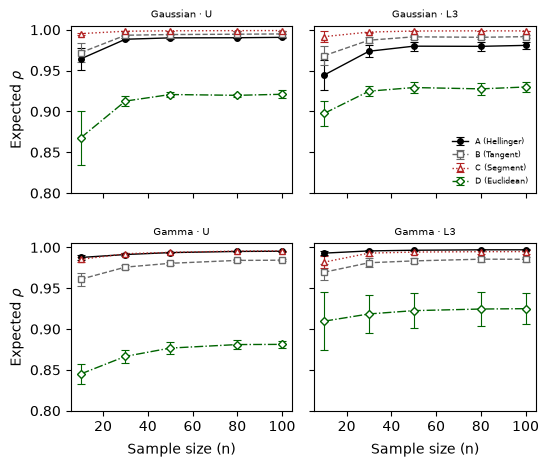

In [41]:
_,_ = plot_panels(
    summaries,
    panels=[
        ("Gaussian", "U"), ("Gaussian", "L3"),
        ("Gamma",    "U"), ("Gamma",    "L3"),
    ],
    ylim=(0.8, 1.005)
)

In [43]:
import numpy as np
import matplotlib.pyplot as plt

METHOD_STYLES = {
    "hellinger": {"label": "A (Hellinger)", "marker": "o", "linestyle": "-",
                  "color": "black", "markerfacecolor": "black",
                  "markeredgecolor": "black"},
    "tangent":   {"label": "B (Tangent)", "marker": "s", "linestyle": "--",
                  "color": "dimgray", "markerfacecolor": "white",
                  "markeredgecolor": "dimgray"},
    "segment":   {"label": "C (Segment)", "marker": "^", "linestyle": ":",
                  "color": "firebrick", "markerfacecolor": "white",
                  "markeredgecolor": "firebrick"},
}

DEFAULT_METHOD_ORDER = ["hellinger", "tangent", "segment"]


def plot_panels(summaries_by_family,
                panels,
                methods=DEFAULT_METHOD_ORDER,
                ylim=(0.85, 1.005),
                y_scale="linear",
                figsize=(6, 5),
                xlabel="Sample size (n)",
                ylabel=r"Expected $\rho$",
                xlabel_pad=6.0, ylabel_pad=4.0,
                wspace=0.1, hspace=0.3,
                title_fontsize=7,
                legend_kwargs=None,
                legend_panel=1):
    """
    Grid 2x2. Cada panel es un par (familia, régimen).
    y_scale: "linear" o "log".
    """
    if legend_kwargs is None:
        legend_kwargs = {"frameon": False, "loc": "lower left", "fontsize": 6}

    fig, axs = plt.subplots(2, 2, figsize=figsize)
    axs_flat = axs.flatten()

    for idx, ax in enumerate(axs_flat):
        if idx >= len(panels):
            ax.set_visible(False)
            continue

        fam, reg = panels[idx]
        row, col = idx // 2, idx % 2

        df = summaries_by_family[fam]
        sub_reg = df[df["regime"] == reg]

        for method in methods:
            sub = sub_reg[sub_reg["method"] == method].sort_values("n")
            if sub.empty:
                continue

            style = METHOD_STYLES.get(method, {
                "label": method, "marker": "o", "linestyle": "-",
                "color": "black", "markerfacecolor": "black",
                "markeredgecolor": "black",
            })

            ns    = sub["n"].to_numpy(dtype=float)
            means = sub["mean"].to_numpy(dtype=float)
            lo    = sub["LB"].to_numpy(dtype=float)
            hi    = sub["UB"].to_numpy(dtype=float)
            yerr  = np.vstack([means - lo, hi - means])

            ax.errorbar(
                ns, means, yerr=yerr,
                marker=style["marker"],
                linestyle=style["linestyle"],
                color=style["color"],
                markerfacecolor=style["markerfacecolor"],
                markeredgecolor=style["markeredgecolor"],
                markersize=4, linewidth=1.0,
                capsize=3, capthick=0.8, elinewidth=0.8,
                label=style["label"],
            )

        ax.set_title(f"{fam} · {reg}", fontsize=title_fontsize)
        ax.set_yscale(y_scale)
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.grid(False)

        if row == 0:
            ax.set_xlabel('')
            ax.tick_params(axis='x', which='both', labelbottom=False)
        else:
            ax.set_xlabel(xlabel, labelpad=xlabel_pad)

        if col == 0:
            ax.set_ylabel(ylabel, labelpad=ylabel_pad)
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', which='both', labelleft=False)

        if idx == legend_panel:
            ax.legend(**legend_kwargs)

    plt.subplots_adjust(wspace=wspace, hspace=hspace)
    plt.show()
    return fig, axs

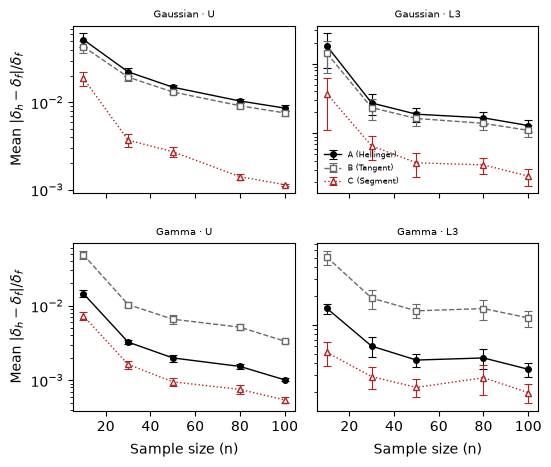

(<Figure size 600x500 with 4 Axes>,
 array([[<Axes: title={'center': 'Gaussian · U'}, ylabel='Mean $|\\delta_h - \\delta_f| / \\delta_f$'>,
         <Axes: title={'center': 'Gaussian · L3'}>],
        [<Axes: title={'center': 'Gamma · U'}, xlabel='Sample size (n)', ylabel='Mean $|\\delta_h - \\delta_f| / \\delta_f$'>,
         <Axes: title={'center': 'Gamma · L3'}, xlabel='Sample size (n)'>]],
       dtype=object))

In [44]:
plot_panels(
    summaries_delta,
    panels=[
        ("Gaussian", "U"), ("Gaussian", "L3"),
        ("Gamma",    "U"), ("Gamma",    "L3"),
    ],
    methods=["hellinger", "tangent", "segment"],
    y_scale="log",
    ylim=None,                # deja que matplotlib elija
    ylabel=r"Mean $|\delta_h - \delta_f| / \delta_f$",
)

In [46]:
for df_name in ["g_gaussian", "g_gamma", "g_beta"]:
    df = globals()[df_name]
    if "delta_rel_err" not in df.columns:
        df["delta_rel_err"] = (
            (df["delta_h"] - df["delta_f"]).abs() / df["delta_f"]
        )
    for k in range(1, 10):
        col = f"rk{k}_rel_err"
        if col not in df.columns:
            df[col] = (df[f"r_h_{k}"] - df[f"r_f_{k}"]).abs() / df[f"r_f_{k}"]

# Verificación
for name in ["g_gaussian", "g_gamma", "g_beta"]:
    cols = [c for c in globals()[name].columns if c.startswith("rk")]
    print(f"{name}: {len(cols)} columnas rk → {cols[:3]}...{cols[-2:]}")

g_gaussian: 9 columnas rk → ['rk1_rel_err', 'rk2_rel_err', 'rk3_rel_err']...['rk8_rel_err', 'rk9_rel_err']
g_gamma: 9 columnas rk → ['rk1_rel_err', 'rk2_rel_err', 'rk3_rel_err']...['rk8_rel_err', 'rk9_rel_err']
g_beta: 9 columnas rk → ['rk1_rel_err', 'rk2_rel_err', 'rk3_rel_err']...['rk8_rel_err', 'rk9_rel_err']


In [47]:
summaries_delta_k9 = {
    "Gaussian": build_summary_delta_k(g_gaussian, k=9),
    "Gamma":    build_summary_delta_k(g_gamma,    k=9),
    "Beta":     build_summary_delta_k(g_beta,     k=9),
}

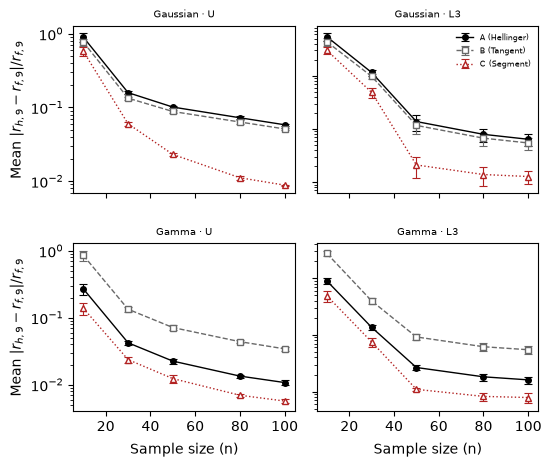

(<Figure size 600x500 with 4 Axes>,
 array([[<Axes: title={'center': 'Gaussian · U'}, ylabel='Mean $|r_{h,9} - r_{f,9}| / r_{f,9}$'>,
         <Axes: title={'center': 'Gaussian · L3'}>],
        [<Axes: title={'center': 'Gamma · U'}, xlabel='Sample size (n)', ylabel='Mean $|r_{h,9} - r_{f,9}| / r_{f,9}$'>,
         <Axes: title={'center': 'Gamma · L3'}, xlabel='Sample size (n)'>]],
       dtype=object))

In [48]:
plot_panels(
    summaries_delta_k9,
    panels=[
        ("Gaussian", "U"), ("Gaussian", "L3"),
        ("Gamma",    "U"), ("Gamma",    "L3"),
    ],
    methods=["hellinger", "tangent", "segment"],
    y_scale="log",
    ylim=None,
    ylabel=r"Mean $|r_{h,9} - r_{f,9}| / r_{f,9}$",
    legend_kwargs={"frameon": False, "loc": "upper right", "fontsize": 6},
)